In [1]:
import torch as th
print(th.__version__, th.cuda.get_device_name(0))
print(th.ones(3, device='cuda:0') * 2)

2.14.1+cu126 Tesla V100-PCIE-32GB
tensor([2., 2., 2.], device='cuda:0')


In [2]:
import sys
print("Python version:", sys.version)

Python version: 3.11.3 | packaged by conda-forge | (main, Apr  6 2023, 08:57:19) [GCC 11.3.0]


In [3]:
import taichi
taichi.init(arch=taichi.gpu)

[Taichi] version 1.7.3, llvm 15.0.4, commit 5ec301be, linux, python 3.11.3


[I 11/20/26 07:40:46.743 212] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout


[Taichi] Starting on arch=cuda


In [4]:
import scatterem
print("Scatterem:", scatterem.__version__)

Scatterem: 0.0.1


In [5]:
from scatterem.operators.basic import Propagator
from scatterem.operators.loss import amplitude_loss
from scatterem import ReconstructionInputs, ReconstructionOptions, reconstruct
from scatterem.models import MultiSlicePtychographyTomographyModel
from scatterem.kernels import update_object_2D
from scatterem.data import RasterScanningDiffractionDataset
from scatterem.util.base import regularize_multilayers
import numpy as np
import torch as th
from scatterem.util.base import energy_to_wavelength as wavelength
import matplotlib.pyplot as plt
from glob import glob
import zarr
import h5py
from numpy.fft import fft, ifft, fftshift
import os
import tifffile

In [6]:
device = 'cuda:0'

In [7]:
base_path = '/dls/science/groups/e02/Joshua/End_to_End_data/'
raw_data_path = base_path + 'Data/'
probe_position_path = base_path + 'Alignment_Results/results/'

In [8]:
raw_data_path

'/dls/science/groups/e02/Joshua/End_to_End_data/Data/'

In [9]:
path_angles = '/dls/science/groups/e02/Joshua/End_to_End_data/Alignment_Results/'
# %% Load the 4D-STEM diffraction patterns and convert the intensity to modulus
M1 = 66
margin = 5
scan_shape = [220, 220]
V_shape1D = scan_shape[0] + M1 + margin * 2

## 2. Load data

### 2.1 Diffraction patterns
Each tilt is a 220×220 scan of 66×66 diffraction patterns. Intensities are converted to amplitudes (`sqrt`) and the detector axes are `fftshift`ed. `error_norm_list` holds the total amplitude of each tilt, which is used to normalise the loss.

In [11]:
take = [171, 173, 175, 177, 179, 183, 184, 186, 188, 190, 192, 194, 196, 198, 200, 202, 204,
        214, 216, 218, 220, 222, 224, 226, 228, 230, 232]   # scan numbers to use
exclude = [204]

scan_numbers = []
measurements_list = []
error_norm_list = []
metadata_list = []

data_files = sorted(glob(raw_data_path + '/*.zip'))
for df in data_files:
    number = int(df.split('/')[-1].split('.')[0])
    if number in exclude or number not in take:
        continue
    store = zarr.open(df, mode='r')
    data = store['/data'][:, :, :, :]#https://github.com/ECLIPSE-Lab/End2EndPtychoTomo_code/blob/main/examples/general_interface_ptychotomo_Te.py
    meta_dict = store['/meta'][0]
    da = np.sqrt(np.fft.fftshift(data, (2, 3)))      # intensity -> amplitude
    error_norm_list.append(th.tensor(np.sum(da)).to(th.float32).to(device))
    measurements_list.append(da)
    metadata_list.append(meta_dict)
    scan_numbers.append(number)
    print(number, data.shape)

print(f'Loaded {len(measurements_list)} tilts: {scan_numbers}')

171 (220, 220, 66, 66)
173 (220, 220, 66, 66)
175 (220, 220, 66, 66)
177 (220, 220, 66, 66)
179 (220, 220, 66, 66)
183 (220, 220, 66, 66)
184 (220, 220, 66, 66)
186 (220, 220, 66, 66)
188 (220, 220, 66, 66)
190 (220, 220, 66, 66)
192 (220, 220, 66, 66)
194 (220, 220, 66, 66)
196 (220, 220, 66, 66)
198 (220, 220, 66, 66)
200 (220, 220, 66, 66)
202 (220, 220, 66, 66)
214 (220, 220, 66, 66)
216 (220, 220, 66, 66)
218 (220, 220, 66, 66)
220 (220, 220, 66, 66)
222 (220, 220, 66, 66)
224 (220, 220, 66, 66)
226 (220, 220, 66, 66)
228 (220, 220, 66, 66)
230 (220, 220, 66, 66)
232 (220, 220, 66, 66)
Loaded 26 tilts: [171, 173, 175, 177, 179, 183, 184, 186, 188, 190, 192, 194, 196, 198, 200, 202, 214, 216, 218, 220, 222, 224, 226, 228, 230, 232]


### 2.2 Tilt-series alignment
Euler angles (phi, theta, psi) and per-tilt translations from the alignment step. Translations are converted from pixels to normalised units (2·t / N).

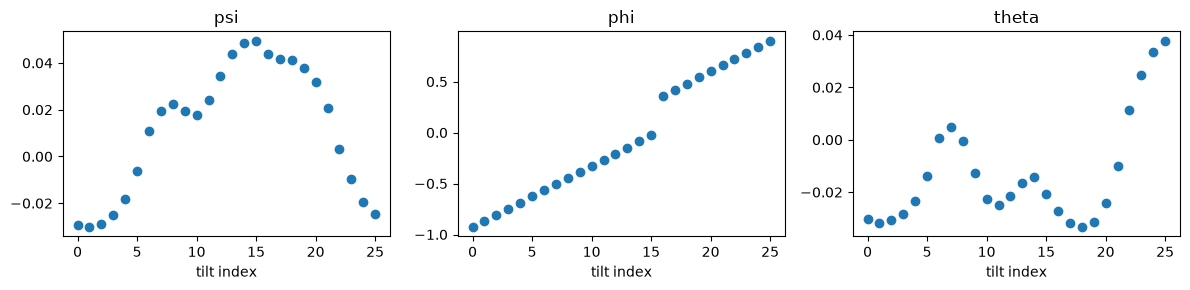

In [12]:
psi = np.load(path_angles + 'psi_astra.npy')
theta = np.load(path_angles + 'theta_astra.npy')
phi = np.load(path_angles + 'phi_astra.npy')
translation_pix = np.load(path_angles + 'translation_astra.npy').T
translation = 2 * translation_pix / V_shape1D

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, vals, name in zip(ax, [psi, phi, theta], ['psi', 'phi', 'theta']):
    a.scatter(np.arange(len(vals)), vals)
    a.set_title(name)
    a.set_xlabel('tilt index')
plt.tight_layout()
plt.show()

### 2.3 Real-space pixel size
dx = 1 / (2·k_max), with k_max taken from the data metadata.

In [13]:
k_max = metadata_list[-1]['k_max'][0]
dx = 1 / 2 / k_max
print('dx =', dx)

dx = 0.396186737848918


### 2.4 Probes and scan positions
These come from the per-tilt MSP reconstructions. `select_inds` picks which stored probe/positions to use for each scan. Positions are converted to pixels, shifted into the padded field of view and rounded. `dr` keeps the sub-pixel remainder, and the two position columns are swapped to match the model's convention.

In [14]:
select_inds = {171: 3, 173: 5, 175: 5, 177: 1, 179: 5, 183: 4, 184: 2, 186: 4, 188: 4,
               190: 3, 192: 6, 194: 5, 196: 3, 198: 6, 200: 5, 202: 6, 204: 5, 214: 1,
               216: 6, 218: 0, 220: 0, 222: 6, 224: 6, 226: 0, 228: 3, 230: 2, 232: 3}

probes_list = []
positions_list = []
dr_list = []

probes_files = sorted(glob(probe_position_path + '/*.h5'))
for df in probes_files:
    number = int(df.split('/')[-1].split('.')[0])
    if number not in scan_numbers:          # keep probes paired with the loaded data
        continue
    with h5py.File(df, 'r') as f:
        probe = f['probe'][select_inds[number]][:, :, :]
        pos = f['best_positions'][select_inds[number]][:, :]

    pos_float = pos / dx + (scan_shape[0] / 2) + margin
    pos_round = np.round(pos_float).astype(np.int64)
    dr_i = pos_round - pos_float

    if probe.shape[1] == M1:
        probes_list.append(probe)
        pt = pos_round.T
        pc = np.zeros_like(pt)
        pc[:, 0] = pt[:, 1]
        pc[:, 1] = pt[:, 0]
        positions_list.append(pc)
        dr_list.append(th.tensor(dr_i.T).to(th.float32))
        print(number, probe.shape, pos.shape)

171 (3, 66, 66) (2, 48400)
173 (3, 66, 66) (2, 48400)
175 (3, 66, 66) (2, 48400)
177 (3, 66, 66) (2, 48400)
179 (3, 66, 66) (2, 48400)
183 (3, 66, 66) (2, 48400)
184 (3, 66, 66) (2, 48400)
186 (3, 66, 66) (2, 48400)
188 (3, 66, 66) (2, 48400)
190 (3, 66, 66) (2, 48400)
192 (3, 66, 66) (2, 48400)
194 (3, 66, 66) (2, 48400)
196 (3, 66, 66) (2, 48400)
198 (3, 66, 66) (2, 48400)
200 (3, 66, 66) (2, 48400)
202 (3, 66, 66) (2, 48400)
214 (3, 66, 66) (2, 48400)
216 (3, 66, 66) (2, 48400)
218 (3, 66, 66) (2, 48400)
220 (3, 66, 66) (2, 48400)
222 (3, 66, 66) (2, 48400)
224 (3, 66, 66) (2, 48400)
226 (3, 66, 66) (2, 48400)
228 (3, 66, 66) (2, 48400)
230 (3, 66, 66) (2, 48400)
232 (3, 66, 66) (2, 48400)


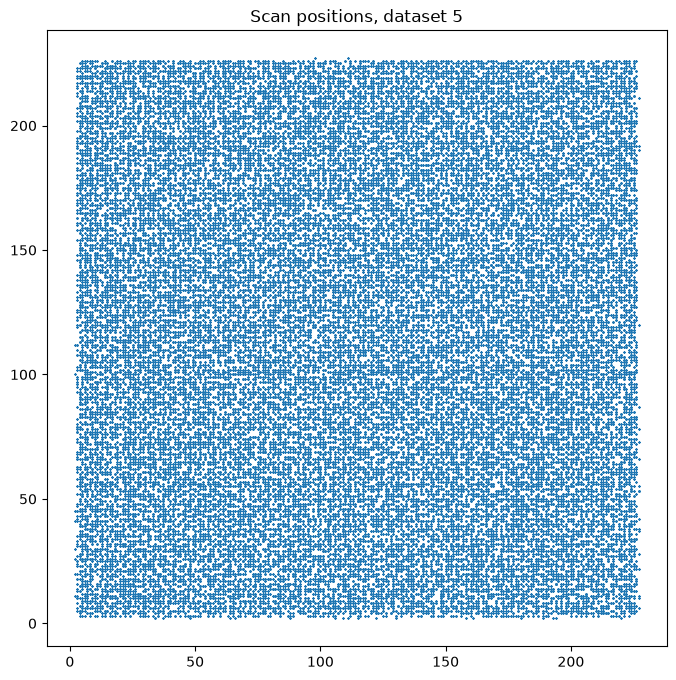

In [15]:
# Check one tilt's scan positions (change ind to look at others)
ind = 5
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(positions_list[ind][:, 0], positions_list[ind][:, 1], marker='x', s=1)
ax.set_title(f'Scan positions, dataset {ind}')
plt.show()

## 3. Preprocess

### 3.1 Scale probe intensity
Each probe is scaled so its total intensity matches the mean total intensity of that tilt's diffraction patterns.

In [16]:
probes_scaled_list = []
for i, probe in enumerate(probes_list):
    probe_int = np.sum(np.abs(probe) ** 2)
    mean_int = np.sum((measurements_list[i] ** 2).mean((0, 1)))
    scaled = probe * np.sqrt(mean_int / probe_int)
    print(f'{i}: probe_int={probe_int:.4g}  mean_int={mean_int:.4g}  '
          f'scaled_int={np.sum(np.abs(scaled) ** 2):.4g}')
    probes_scaled_list.append(scaled)

probes_scaled = th.as_tensor(np.array(probes_scaled_list))

0: probe_int=16.7  mean_int=1773  scaled_int=1773
1: probe_int=16.9  mean_int=1738  scaled_int=1738
2: probe_int=17.07  mean_int=1757  scaled_int=1757
3: probe_int=16.03  mean_int=1740  scaled_int=1740
4: probe_int=16.98  mean_int=1737  scaled_int=1737
5: probe_int=16.96  mean_int=1743  scaled_int=1743
6: probe_int=16.52  mean_int=1737  scaled_int=1737
7: probe_int=16.68  mean_int=1723  scaled_int=1723
8: probe_int=16.85  mean_int=1723  scaled_int=1723
9: probe_int=16.36  mean_int=1734  scaled_int=1734
10: probe_int=15.7  mean_int=1722  scaled_int=1722
11: probe_int=16.12  mean_int=1719  scaled_int=1719
12: probe_int=15.9  mean_int=1723  scaled_int=1723
13: probe_int=16.37  mean_int=1723  scaled_int=1723
14: probe_int=16.09  mean_int=1707  scaled_int=1707
15: probe_int=15.22  mean_int=1581  scaled_int=1581
16: probe_int=16.86  mean_int=1722  scaled_int=1722
17: probe_int=15.43  mean_int=1701  scaled_int=1701
18: probe_int=16.52  mean_int=1721  scaled_int=1721
19: probe_int=16.46  mean_

### 3.2 Sanity checks
Data, probes and positions must have the same count and be in the same order. Positions should stay inside the padded volume (0 … V_shape1D − M1).

In [17]:
n = len(measurements_list)
print('tilts (data): ', n)
print('probes:       ', len(probes_scaled))
print('positions:    ', len(positions_list))
print('angles:       ', len(phi))
print('translations: ', len(translation))
if not (n == len(probes_scaled) == len(positions_list)):
    print('WARNING: data, probes and positions counts differ')

for i, posi in enumerate(positions_list):
    print(i, posi.min(0), posi.max(0))

tilts (data):  26
probes:        26
positions:     26
angles:        26
translations:  26
0 [2 2] [227 227]
1 [2 2] [227 227]
2 [2 2] [227 227]
3 [2 2] [227 228]
4 [2 2] [228 227]
5 [2 2] [227 227]
6 [2 2] [227 227]
7 [2 2] [227 227]
8 [2 2] [227 227]
9 [1 2] [227 227]
10 [1 2] [228 228]
11 [2 2] [227 227]
12 [1 1] [227 228]
13 [2 2] [227 228]
14 [2 2] [227 227]
15 [2 2] [227 227]
16 [2 2] [227 227]
17 [2 1] [228 227]
18 [2 2] [228 227]
19 [2 2] [227 227]
20 [2 2] [227 227]
21 [2 2] [227 227]
22 [2 2] [227 227]
23 [2 2] [227 227]
24 [2 2] [227 227]
25 [2 2] [227 227]


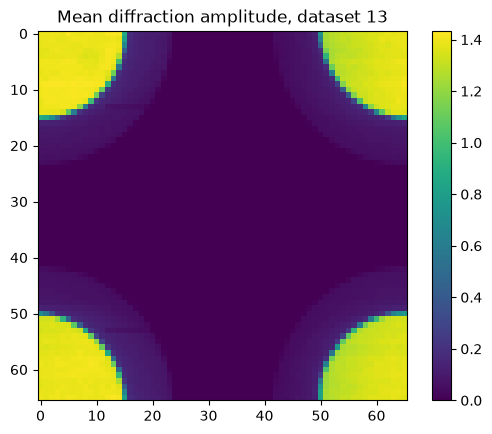

In [18]:
# Mean diffraction amplitude for one tilt
ind = 13
fig, ax = plt.subplots()
im = ax.imshow(measurements_list[ind].mean((0, 1)))
ax.set_title(f'Mean diffraction amplitude, dataset {ind}')
plt.colorbar(im)
plt.show()

### 3.3 Flatten the scan dimensions
(220, 220, 66, 66) → (48400, 66, 66). The result is a view, so it uses no extra memory, and `measurements_list` stays 4D for the cells above.

In [19]:
measurements_flat = []
for mi in measurements_list:
    ms = mi.shape
    measurements_flat.append(th.as_tensor(mi).view(ms[0] * ms[1], ms[2], ms[3]))
print(measurements_flat[0].shape)

torch.Size([48400, 66, 66])


## 4. Build the model

### 4.1 Volume and multislice geometry
The potential volume starts as zeros (296³, complex). The beam direction is split into 8 slices, so each slice is `bin_factor` voxels thick. The beam energy is 80 keV.

In [21]:
V_shape = (V_shape1D, V_shape1D, V_shape1D)
V_model = th.zeros(V_shape, dtype=th.complex64).unsqueeze(0).to(device)

slice_number = 1
bin_factor = V_shape1D // slice_number
slice_thickness = bin_factor * dx
print('bin_factor:', bin_factor, '  slice_thickness:', slice_thickness)

E = 80e3                 # beam energy (eV)
lam = wavelength(E)
dx_xy = [dx, dx]         # pixel size along both axes, for the propagator
shape = (M1, M1)

bin_factor: 296   slice_thickness: 117.27127440327973


In [22]:
# Problem sizes
Nmodes = probes_scaled[0].shape[0]                 # probe modes
B = 1
N = th.tensor([V_shape[0], V_shape[2]]).int()     # volume lateral size
M = th.tensor([M1, M1]).int()                     # probe window size
K = positions_list[0].shape[0]                    # scan positions per tilt
print('Nmodes:', Nmodes)
print('B:     ', B)
print('N:     ', N)
print('M:     ', M)
print('K:     ', K)

Nmodes: 3
B:      1
N:      tensor([296, 296], dtype=torch.int32)
M:      tensor([66, 66], dtype=torch.int32)
K:      48400


### 4.2 PSF kernel for the binning regularisation
A smoothing kernel built with `regularize_multilayers` and cropped around its centre. The model uses it to regularise the effect of binning voxels into slices.

In [23]:
import torch as th
print(th.__version__, th.cuda.get_arch_list())
print(th.ones(3, device='cuda:0') * 2)   # a real GPU operation

2.14.1+cu126 ['sm_50', 'sm_60', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']
tensor([2., 2., 2.], device='cuda:0')


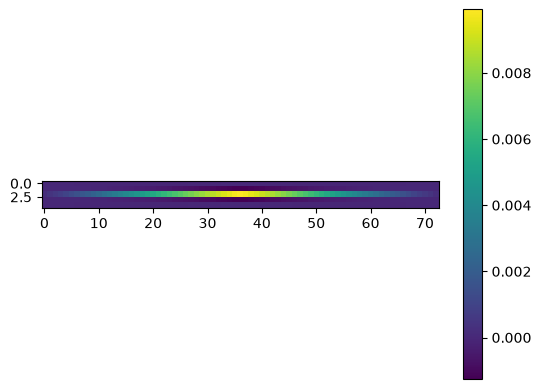

kernel shape: torch.Size([1, 5, 73, 5])


In [24]:
kernel_num = 297
psf_shape = 297
kernel_shape = [kernel_num, kernel_num, kernel_num]
psf = np.zeros([psf_shape, psf_shape, psf_shape])
psf[0, 0, 0] = 1

Wa = regularize_multilayers(kernel_shape, 90, alpha=1)
psf2 = np.fft.ifftn(np.fft.fftn(psf) * Wa).real

m0, m1, m2 = 146, 112, 146
psf3 = fftshift(psf2)[m2:-m2, m0:-m0, m1:-m1]
psfimg = fftshift(psf2[0])[m0:-m0, m1:-m1]

fig, ax = plt.subplots()
im = ax.imshow(psfimg)
plt.colorbar(im)
plt.show()

kernel = th.as_tensor(np.swapaxes(psf3, 1, 2)).unsqueeze(0).to(device)
print('kernel shape:', kernel.shape)

### 4.3 Move inputs to the GPU
Angles, translations, positions, probes and the Fresnel propagator.

In [25]:
n_angles = len(phi)
angles = th.zeros((3, n_angles), device=device)
angles[0, :] = th.as_tensor(phi).to(device)
angles[1, :] = th.as_tensor(theta).to(device)
angles[2, :] = th.as_tensor(psi).to(device)

start_end = [[[0, V_shape[0]], [0, V_shape[2]]]] * n_angles
translations = [th.tensor([[ti[0]], [ti[1]]], device=device) for ti in translation]
positions = [th.as_tensor(posi).to(device) for posi in positions_list]
dr = dr_list
error_norm = error_norm_list
probe_model = [[th.as_tensor(p).unsqueeze(1).to(device).requires_grad_(False)]
               for p in probes_scaled]
propagator = Propagator(slice_thickness, lam, dx_xy, shape, device=device)

error_norm_total = th.sum(th.stack(error_norm)).clone().cpu().numpy()

### 4.4 Create the model
`tau1`, `tau2` are model hyper-parameters, and `braggpix` / `butterorder` set the Butterworth filter. If you rebuild the model after a run, re-run 4.1 first so the volume starts from zeros again.

In [26]:
tau1 = 1e-9
tau2 = 3e-9
braggpix = 113
butterorder = 5

model = MultiSlicePtychographyTomographyModel(V_model,
                                              probe_model,
                                              positions,
                                              dr,
                                              error_norm,
                                              angles=angles,
                                              tau1=tau1,
                                              tau2=tau2,
                                              translations=translations,
                                              start_end_model=start_end,
                                              loss_function=amplitude_loss,
                                              propagator=propagator,
                                              braggpix=braggpix,
                                              butterorder=butterorder,
                                              dx=dx,
                                              bin_factor=bin_factor,
                                              intensity_scaling_factor=1,
                                              kernel=kernel,
                                              subpix_shift=False)

### 4.5 Datasets
One dataset per tilt, each linked to its angle, translation and start/end index.

In [27]:
datasets = [
    RasterScanningDiffractionDataset(m, probe_index=0, angles_index=i,
                                     translation_index=i, start_end_index=i)
    for i, m in enumerate(measurements_flat)
]
print(len(datasets), 'datasets')

26 datasets


### 4.6 Reconstruction options

In [28]:
num_ite = 1            
n_batches = 5
batch_size = measurements_flat[0].shape[0] // n_batches

options = ReconstructionOptions()
options.optimize_probe = lambda it: it > -1     # optimise from the first iteration
options.optimize_sample = lambda it: it > -1
options.num_iterations = num_ite
options.update_object_function = update_object_2D
options.probe_optimizer_parameters = {'lr': 6e-5, 'momentum': 0.4}
options.object_optimizer_parameters = {'lr': 4e-5, 'momentum': 0.5}
options.batch_size = batch_size
# options.upper_limit = 1.3

options.after_iteration_hooks = []
options.after_batch_hooks = []
options.after_dataset_hooks = []

print('batch_size:', batch_size)

batch_size: 9680


## 5. Run and save

### 5.1 Reconstruct
This is the long-running cell.

In [ ]:
inputs = ReconstructionInputs(model=model, datasets=datasets)
results = reconstruct(inputs, options)

/dls/science/groups/e02/Joshua/End2EndPtychoTomo_code/scatterem/operators/split.py:88: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  grid = F.affine_grid(R, out_size)
/dls/science/groups/e02/Joshua/End2EndPtychoTomo_code/scatterem/operators/split.py:91: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  out = F.grid_sample(vol.expand(n_theta, 1, vol.shape[2], vol.shape[3], vol.shape[4]), grid_partial)#, padding_mode="border")


### 5.2 Save the volume and plot the loss

In [ ]:
output_file = '/dls/science/groups/e02/Joshua/End_to_End_data/Te_8slice_astra_test_32.tif'
os.makedirs(os.path.dirname(output_file), exist_ok=True)

t1 = results.V[0].real.astype(np.float32)      # 3D volume, shape (296, 296, 296)
tifffile.imwrite(
    output_file, t1,
    imagej=True,                                 # opens as a 3D stack in Fiji
    resolution=(1 / dx, 1 / dx),                 # voxel size, so scale bars are right
    metadata={'spacing': dx, 'unit': 'angstrom', 'axes': 'ZYX'},
)
print('saved', t1.shape, 'to', output_file)
# np.save(output_file.replace('.tif', '.npy'), t1)   # uncomment to also keep a .npy copy

losses_np = np.array(results.losses / error_norm_total)   # one value per iteration
plt.plot(losses_np, 'o-')
plt.xlabel('iteration')
plt.ylabel('normalised loss')
plt.show()

In [43]:
vol = np.load(output_file)
c = vol.shape[0] // 2

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for i in range(3):
    ax[0, i].imshow(np.take(vol, c, axis=i), cmap='gray'); ax[0, i].set_title(f'central slice, axis {i}')
    ax[1, i].imshow(vol.sum(axis=i), cmap='gray');        ax[1, i].set_title(f'projection, axis {i}')
plt.tight_layout()
plt.show()

ValueError: This file contains pickled (object) data. If you trust the file you can load it unsafely using the `allow_pickle=` keyword argument or `pickle.load()`.